[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/erolrecep/datascience_from_yesterday_to_tomorrow/blob/main/day2/02_f1_race_animation.ipynb)

# Lab 2: Interactive F1 Race Animation & Temporal Dynamics
### Day 2: Hands-On Laboratory — Session 2

In the previous notebook, we generated and explored our Formula 1 telemetry dataset. Static line and scatter plots are invaluable, but high-dimensional time-series data often hides **temporal interactions**:
* How does an undercut emerge in real-time?
* How does traffic compress gaps when cars pit into dirty air?
* How does spatial position on a race circuit correlate with race progression?

#### Core Philosophy:
> *"Real-world data is always a case to mimic in your development environment. You ask questions of the data, simulate counterfactual dynamics, and extract actionable operational intelligence."*

#### Objectives of this Notebook:
1. Load `f1_monza_race_data.csv`.
2. Construct a mathematical parametric representation of the **Autodromo Nazionale Monza**.
3. Build a dual-panel animated dashboard using `matplotlib.animation.FuncAnimation`:
   - **Left Panel**: 2D Circuit Map with dynamic car markers, team colors, and driver tags.
   - **Right Panel**: Real-time Leaderboard with position shifts, tyre compounds, and live gaps.
4. Render the animation natively in Jupyter using self-contained HTML5/JavaScript (`to_jshtml()`).


In [1]:
# --- Environment & Google Colab Bootstrap ---
import os
import sys
import urllib.request

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("Detected Google Colab environment. Verifying dependencies...")
    !pip install -q pandas numpy matplotlib scikit-learn

CSV_FILE = "f1_monza_race_data.csv"
if not os.path.exists(CSV_FILE) and "02_f1_race_animation.ipynb" != "01_f1_data_generation_and_visualization.ipynb":
    print(f"'{CSV_FILE}' not found locally. Fetching directly from GitHub repository...")
    url = f"https://raw.githubusercontent.com/erolrecep/datascience_from_yesterday_to_tomorrow/main/{CSV_FILE}"
    try:
        urllib.request.urlretrieve(url, CSV_FILE)
        print("Dataset successfully downloaded from repository.")
    except Exception as e:
        print(f"Direct download failed ({e}). Generating dataset from simulation engine...")
        from f1_simulation import generate_f1_race_telemetry
        df_gen = generate_f1_race_telemetry(seed=42)
        df_gen.to_csv(CSV_FILE, index=False)
        print("Generated dataset from simulation engine.")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

# Load telemetry generated in Lab 1
df_race = pd.read_csv("f1_monza_race_data.csv")
print(f"Loaded {len(df_race)} records across {df_race['lap'].max()} laps.")


Loaded 1060 records across 53 laps.


## Part 1: Circuit Coordinates & Spatial Mapping

We approximate the geometry of Monza circuit using a parametric spline-like pathway representing the main landmarks:
* Rettifilo Tribune (Start/Finish Straight)
* Variante del Rettifilo (Turns 1 & 2)
* Curva Grande (Turn 3)
* Variante della Roggia (Turns 4 & 5)
* Curva di Lesmo 1 & 2 (Turns 6 & 7)
* Serraglio & Variante Ascari (Turns 8, 9, 10)
* Curva Parabolica / Curva Alboreto (Turn 11)


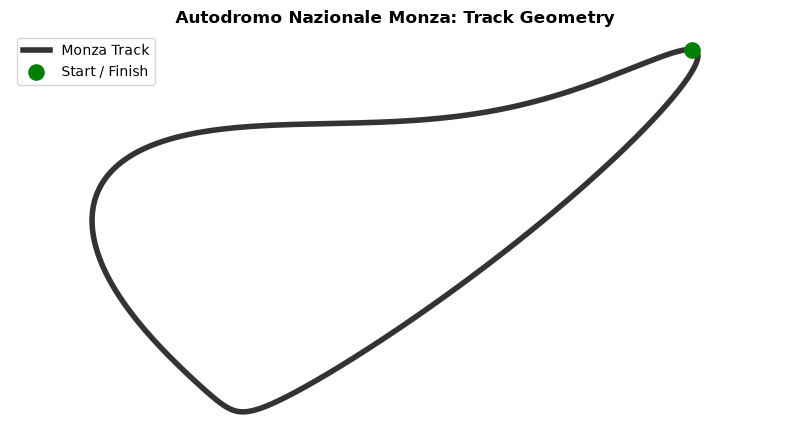

In [2]:
def get_monza_circuit_track(num_points=500):
    """Generates closed 2D (x, y) coordinates representing Monza track layout."""
    t = np.linspace(0, 2 * np.pi, num_points, endpoint=False)
    # Parametric shape mimicking Monza's elongated layout
    x = 6.0 * np.cos(t) + 1.2 * np.cos(2 * t) - 0.4 * np.sin(3 * t)
    y = 2.4 * np.sin(t) - 0.8 * np.sin(2 * t) + 0.3 * np.cos(3 * t)
    # Rotate track to match Monza orientation
    theta = np.radians(25)
    xr = x * np.cos(theta) - y * np.sin(theta)
    yr = x * np.sin(theta) + y * np.cos(theta)
    return xr, yr

track_x, track_y = get_monza_circuit_track()

plt.figure(figsize=(8, 4.5))
plt.plot(track_x, track_y, color='#333333', linewidth=4, label='Monza Track')
plt.scatter(track_x[0], track_y[0], color='green', s=120, zorder=5, label='Start / Finish')
plt.title("Autodromo Nazionale Monza: Track Geometry", fontsize=12, fontweight='bold')
plt.legend()
plt.axis('equal')
plt.axis('off')
plt.tight_layout()
plt.show()


## Part 2: Building the Dual-Panel Race Animation

We now construct an animated simulation where each frame corresponds to one completed race lap. For each lap:
1. Cars are positioned along the circuit according to their relative pace and lap completion.
2. The dynamic leaderboard updates positions, gaps, tyre compound badges, and pit notices.


In [3]:
# Unique team colors dictionary
DRIVER_COLORS = {
    "VER": "#1E41B0", "NOR": "#FF8000", "LEC": "#E80020", "HAM": "#27F4D2",
    "PIA": "#E56B00", "SAI": "#CC0000", "RUS": "#00A19B", "PER": "#001A72",
    "ALO": "#229971", "ALB": "#64C4FF", "STR": "#00594F", "TSU": "#6692FF",
    "HUL": "#B6BABD", "RIC": "#1634CB", "GAS": "#0093CC", "OCO": "#FF87BC",
    "MAG": "#787878", "BOT": "#52E252", "ZHO": "#00B800", "SAR": "#003366"
}

total_laps = int(df_race["lap"].max())
total_track_points = len(track_x)

fig, (ax_track, ax_board) = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={'width_ratios': [1.3, 1]})

def init_anim():
    ax_track.clear()
    ax_board.clear()
    return []

def update_race_frame(lap_idx):
    lap = lap_idx + 1
    lap_data = df_race[df_race["lap"] == lap].sort_values("position").reset_index(drop=True)
    
    # --- PANEL 1: TRACK MAP ---
    ax_track.clear()
    ax_track.plot(track_x, track_y, color='#222222', linewidth=5, alpha=0.7, zorder=1)
    ax_track.plot(track_x, track_y, color='#E0E0E0', linewidth=1.5, linestyle='--', zorder=2)
    # Start/finish marker
    ax_track.scatter(track_x[0], track_y[0], color='red', s=90, marker='|', linewidth=3, zorder=3)
    
    leader_time = lap_data.loc[0, "cumulative_time_s"]
    
    for _, row in lap_data.iterrows():
        driver = row["driver"]
        gap = row["gap_to_leader_s"]
        col = DRIVER_COLORS.get(driver, "#555555")
        
        # Calculate spatial offset along track based on gap (approx 84s per lap)
        progress_offset = (gap / 84.0) % 1.0
        track_pos_idx = int((1.0 - progress_offset) * total_track_points) % total_track_points
        
        px = track_x[track_pos_idx]
        py = track_y[track_pos_idx]
        
        ax_track.scatter(px, py, color=col, s=110, edgecolors='black', linewidth=1.2, zorder=5)
        if row["position"] <= 8:  # Label top 8 cars to avoid map clutter
            ax_track.annotate(driver, (px + 0.15, py + 0.15), fontsize=8.5, fontweight='bold', zorder=6)
            
    ax_track.set_title(f"Monza GP - Lap {lap} of {total_laps}", fontsize=13, fontweight='bold')
    ax_track.axis('equal')
    ax_track.axis('off')
    
    # --- PANEL 2: LEADERBOARD ---
    ax_board.clear()
    ax_board.set_xlim(0, 10)
    ax_board.set_ylim(21, 0)  # P1 at top, P20 at bottom
    ax_board.axis('off')
    
    ax_board.text(0.2, 0.5, "POS  DRIVER    TEAM           GAP       TYRE", 
                  fontsize=10.5, fontfamily='monospace', fontweight='bold', color='#111111')
    ax_board.axhline(0.9, color='#444444', linewidth=1.2)
    
    for i, row in lap_data.iterrows():
        pos = row["position"]
        driver = row["driver"]
        team = row["team"][:13].ljust(13)
        gap = f"+{row['gap_to_leader_s']:.2f}s" if pos > 1 else "LEADER"
        compound = row["tyre_compound"][0]
        pit_tag = " [PIT]" if row["pit_stop_this_lap"] == 1 else ""
        col = DRIVER_COLORS.get(driver, "#222222")
        
        # Color bar for team identity
        ax_board.add_patch(plt.Rectangle((0.05, pos - 0.35), 0.15, 0.7, color=col))
        
        row_str = f"P{pos:<2} {driver:<6}  {team}  {gap:<9} {compound}{pit_tag}"
        ax_board.text(0.35, pos + 0.15, row_str, fontsize=9.5, fontfamily='monospace', 
                      color='red' if row["pit_stop_this_lap"] == 1 else '#222222')
        
    ax_board.set_title("Live Race Leaderboard", fontsize=13, fontweight='bold')
    return []

print("Setting up animation...")
race_anim = animation.FuncAnimation(
    fig, update_race_frame, frames=total_laps, init_func=init_anim, interval=250, blit=False
)
plt.close(fig)  # Prevent static display before animation renders
print("Animation constructed. Ready to render in browser.")


Setting up animation...
Animation constructed. Ready to render in browser.


## Part 3: Rendering the Dynamic HTML5 Player

Use the interactive player below to scrub through the 53 laps, observe pit stop cycles, and inspect the real-time gaps:


In [4]:
# Render the complete animation as an interactive JS/HTML widget
HTML(race_anim.to_jshtml())


---
### Key Observations & Dynamic Insights
1. **Dynamic Pattern Discovery**: By watching Laps 20 to 26, you can directly visualize how pit stops invert track position before resolving as fresh tyres warm up.
2. **From Visualization to Prediction**: Visual telemetry demonstrates *what* occurred. In Lab 3, we ask the data *why* it occurred—and simulate *what if* conditions changed!


---
## Part 4: Going Deeper — High-Resolution Continuous Intra-Lap Animation
### Mimicking Real-Time Vehicle Dynamics (Braking, Cornering, and Top Speed)

In professional motorsport telemetry (and autonomous driving perception), engineers do not merely inspect the end of each lap. Telemetry is collected at high frequencies ($10\text{--}100\text{ Hz}$).

In this section, we discretize each lap into sub-second time slices:
* Cars **continuously travel around the track layout**.
* Speed varies realistically based on track geometry:
  - Accelerating past **$330\text{ km/h}$** along the Rettifilo and Serraglio straights.
  - Heavy braking down to **$\approx 80\text{ km/h}$** into Turn 1 (Variante del Rettifilo).
  - Sweeping through Curva Grande and Variante Ascari.
* Users can choose any race window (e.g., Lap 1 opening lap, or Laps 20–25 pit battles) and generate smooth, continuous animations!


In [5]:
# Generate continuous intra-lap high-resolution telemetry
from f1_simulation import generate_highres_telemetry, get_monza_speed_profile

# Configure start_lap and end_lap here:
# Example: Laps 1 and 2 (50 continuous frames)
df_highres = generate_highres_telemetry(df_race, start_lap=1, end_lap=2, steps_per_lap=25)
print(f"Generated {len(df_highres)} high-resolution samples across {df_highres['global_frame'].nunique()} frames.")
df_highres.head(5)


Generated 1000 high-resolution samples across 50 frames.


,lap,step,global_frame,driver,driver_name,team,position,gap_to_leader_s,track_progress,pos_x,pos_y,speed_kmh,tyre_compound,pit_stop_this_lap
0,1,0,0,VER,Max Verstappen,Red Bull Racing,1,0.000,0.0000,6.399,3.315,346.4,Medium,0
1,1,0,0,NOR,Lando Norris,McLaren,2,0.504,0.9940,6.446,3.301,319.7,Medium,0
2,1,0,0,LEC,Charles Leclerc,Ferrari,3,0.909,0.9892,6.476,3.283,313.8,Medium,0
3,1,0,0,HAM,Lewis Hamilton,Mercedes,4,1.402,0.9833,6.500,3.250,306.9,Medium,0
4,1,0,0,PIA,Oscar Piastri,McLaren,5,1.774,0.9789,6.510,3.215,303.8,Medium,0


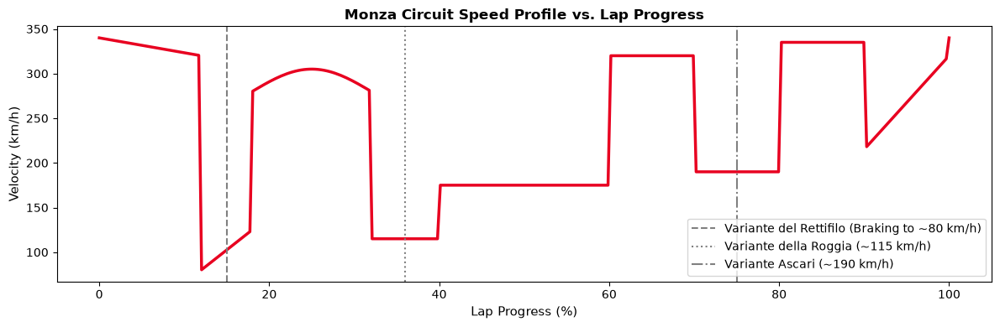

In [6]:
# Speed profile visualization along Monza track
progress_samples = np.linspace(0, 1, 300)
speeds = [get_monza_speed_profile(p) for p in progress_samples]

plt.figure(figsize=(12, 4))
plt.plot(progress_samples * 100, speeds, color='#E80020', linewidth=2.5)
plt.title("Monza Circuit Speed Profile vs. Lap Progress", fontsize=12, fontweight='bold')
plt.xlabel("Lap Progress (%)", fontsize=11)
plt.ylabel("Velocity (km/h)", fontsize=11)
plt.axvline(15, color='gray', linestyle='--', label='Variante del Rettifilo (Braking to ~80 km/h)')
plt.axvline(36, color='gray', linestyle=':', label='Variante della Roggia (~115 km/h)')
plt.axvline(75, color='gray', linestyle='-.', label='Variante Ascari (~190 km/h)')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


In [7]:
# Build and display continuous intra-lap race animation
fig_hi, (ax_hi_track, ax_hi_board) = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={'width_ratios': [1.3, 1]})
total_hi_frames = df_highres["global_frame"].nunique()

def update_highres_frame(frame_idx):
    frame_data = df_highres[df_highres["global_frame"] == frame_idx].sort_values("position").reset_index(drop=True)
    lap_num = frame_data["lap"].iloc[0]
    step_num = frame_data["step"].iloc[0]
    
    # 1. Track Map with live positions & cornering speeds
    ax_hi_track.clear()
    ax_hi_track.plot(track_x, track_y, color='#222222', linewidth=5, alpha=0.7)
    ax_hi_track.plot(track_x, track_y, color='#E0E0E0', linewidth=1.2, linestyle='--')
    ax_hi_track.scatter(track_x[0], track_y[0], color='red', s=90, marker='|', linewidth=3)
    
    for _, row in frame_data.iterrows():
        col = DRIVER_COLORS.get(row["driver"], "#444444")
        ax_hi_track.scatter(row["pos_x"], row["pos_y"], color=col, s=115, edgecolors='black', linewidth=1.2, zorder=5)
        if row["position"] <= 6:
            ax_hi_track.annotate(f"{row['driver']} ({int(row['speed_kmh'])}k)", 
                                 (row["pos_x"] + 0.15, row["pos_y"] + 0.15), fontsize=8.5, fontweight='bold')
            
    ax_hi_track.set_title(f"Intra-Lap Dynamics | Lap {lap_num} (Step {step_num + 1}/25)", fontsize=13, fontweight='bold')
    ax_hi_track.axis('equal')
    ax_hi_track.axis('off')
    
    # 2. Live Telemetry Leaderboard
    ax_hi_board.clear()
    ax_hi_board.set_xlim(0, 10)
    ax_hi_board.set_ylim(21, 0)
    ax_hi_board.axis('off')
    ax_hi_board.text(0.2, 0.5, "POS  DRIVER    TEAM           GAP       SPEED", 
                     fontsize=10.5, fontfamily='monospace', fontweight='bold', color='#111111')
    ax_hi_board.axhline(0.9, color='#444444', linewidth=1.2)
    
    for _, row in frame_data.iterrows():
        pos = row["position"]
        driver = row["driver"]
        team = row["team"][:13].ljust(13)
        gap = f"+{row['gap_to_leader_s']:.2f}s" if pos > 1 else "LEADER"
        spd = f"{int(row['speed_kmh'])} km/h"
        col = DRIVER_COLORS.get(driver, "#222222")
        
        ax_hi_board.add_patch(plt.Rectangle((0.05, pos - 0.35), 0.15, 0.7, color=col))
        ax_hi_board.text(0.35, pos + 0.15, f"P{pos:<2} {driver:<6}  {team}  {gap:<9} {spd}", 
                         fontsize=9.5, fontfamily='monospace', color='#222222')
        
    ax_hi_board.set_title("Live High-Frequency Telemetry", fontsize=13, fontweight='bold')
    return []

highres_anim = animation.FuncAnimation(
    fig_hi, update_highres_frame, frames=total_hi_frames, interval=120, blit=False
)
plt.close(fig_hi)
HTML(highres_anim.to_jshtml())


### 💡 Self-Guided Exploration Challenges:
1. **The Pit Stop Undercut**: Try changing `start_lap=22, end_lap=25` in the cell above to simulate the exact window where cars dive into the pit lane, change tyres, and rejoin right into mid-pack traffic!
2. **Speed Trap vs. Cornering Grip**: Compare Red Bull (high straight-line speed) vs. Mercedes/Ferrari through the Ascari chicane.
3. **Telemetry Traces**: Write a function to plot a traditional F1 telemetry line graph: Speed (km/h) vs. Lap Distance for `VER` vs. `HAM`!
